# CNN Evaluation and Visualization

This notebook evaluates the performance of a trained Convolutional Neural Network (CNN) for deepfake detection. We will:
- Load the trained EfficientNet model and the processed test dataset
- Compute and visualize evaluation metrics (accuracy, precision, recall, F1-score)
- Generate a classification report and confusion matrix
- Plot the ROC curve and show loss/accuracy curves from training

All steps are thoroughly commented to help you understand the workflow and design decisions.

## Preparation

We begin by importing all necessary Python libraries. Most are standard for PyTorch deep learning workflows and data analysis:
- `torch`/`torchvision`: For model loading and tensor operations
- `sklearn.metrics`: For easy calculation of classification metrics
- `matplotlib`/`pandas`/`numpy`: For data wrangling and visualization
- `tqdm`: To show progress bars for batch operations
- `PIL.ImageFile`: To handle any truncated image files during dataset loading

We also set up device selection (GPU if available), batch size, and file paths.

In [1]:
import os
import json
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_curve, auc
from torchvision.utils import save_image
from tqdm import tqdm
from PIL import ImageFile

# This fixes errors when loading images that are truncated (very common in large image datasets)
ImageFile.LOAD_TRUNCATED_IMAGES = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
NUM_WORKERS = 2
MODEL_PATH = 'checkpoints/CNN/model_final.pth'
TESTSET_PATH = 'data/processed/test_dataset.pt'
OUTPUT_DIR = "output/CNN"


## Load Model and Test Data

We now load the trained EfficientNet-B0 model from disk. 
Notice that we must re-instantiate the model architecture with the correct final layer (2 output classes for binary classification). Only after modifying the architecture do we load the trained weights.

Then, we load the preprocessed test dataset, which was previously saved using PyTorch's `torch.save`. We use a DataLoader for efficient batch processing.

In [2]:
# Load the default EfficientNet-B0 weights for base
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace the classifier layer for binary output (fake/real)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE).eval()  # Switch to evaluation mode

# Load test set
test_dataset = torch.load(TESTSET_PATH, weights_only=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


## Metrics Evaluation

This block runs inference on the entire test set, collecting:
- Softmax probabilities for the 'real' class (for ROC/AUC analysis)
- Predicted class labels
- True labels

If a batch fails to process (e.g., due to a corrupt image), the code will skip it and report the error. This ensures evaluation is robust to data issues.

At the end, all predictions are concatenated and we calculate the core classification metrics: accuracy, precision, recall, and F1-score.

In [3]:
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating"):
        try:
            imgs = imgs.to(DEVICE)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]  # Probability of 'real'
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.numpy())
        except OSError as e:
            print(f"Erro ao processar batch — {str(e)}. Pulando este batch.")
            continue

# Convert lists to numpy arrays for metric computation
y_true = np.array(all_labels)
y_pred = np.array(all_preds)
probs = np.array(all_probs)

print("Accuracy:", (y_pred == y_true).mean())
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))


Evaluating: 100%|██████████| 375/375 [16:05<00:00,  2.58s/it]

Accuracy: 0.9123947653580061
Precision: 0.902375528799219
Recall: 0.9247957311989328
F1 Score: 0.9134480770814462


## Save Probabilities and Labels

We save the predicted probabilities and ground-truth labels to disk as NumPy arrays. These files can be used later for ensemble modeling or for comparison across models (e.g., CNN vs. ViT).

In [4]:
np.save("output/cnn_probs.npy", probs)
np.save("output/true_labels.npy", y_true)

## Graphs And Reports

Here we construct a Pandas DataFrame from the sklearn classification report dictionary for a nicer presentation of per-class precision/recall/F1 and support.

In [5]:
report_df = pd.DataFrame(classification_report(y_true, y_pred, target_names=['fake', 'real'], output_dict=True)).transpose()
report_df

,precision,recall,f1-score,support
fake,0.922919,0.900000,0.911316,6000.000000
real,0.902376,0.924796,0.913448,5997.000000
accuracy,0.912395,0.912395,0.912395,0.912395
macro avg,0.912647,0.912398,0.912382,11997.000000
weighted avg,0.912650,0.912395,0.912382,11997.000000


## Confusion Matrix and ROC curve

We plot the confusion matrix, which shows the number of correct and incorrect predictions for each class. This is followed by the ROC curve, which helps visualize the trade-off between true and false positive rates as the classification threshold varies. The Area Under Curve (AUC) summarizes the model's ranking ability.

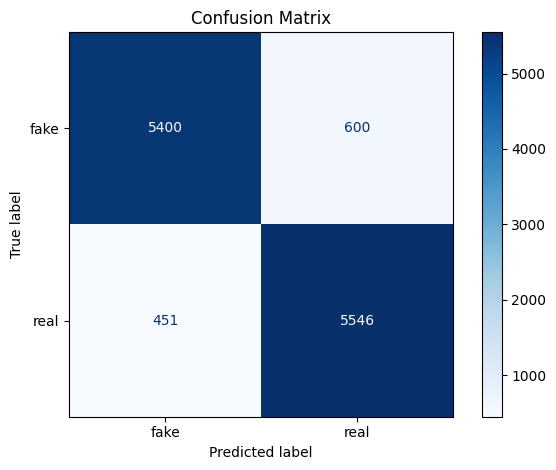

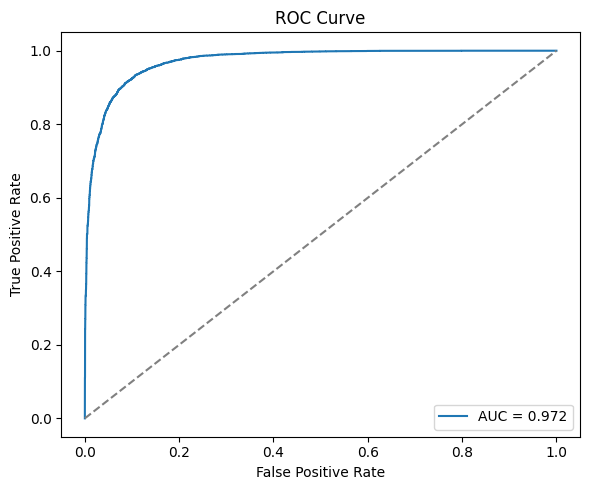

In [6]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['fake', 'real'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_true, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


## Training Curves

Finally, we load the metrics recorded during training (train/validation loss and accuracy per epoch) and plot them. This helps diagnose overfitting/underfitting and the effectiveness of learning rate schedules or early stopping.

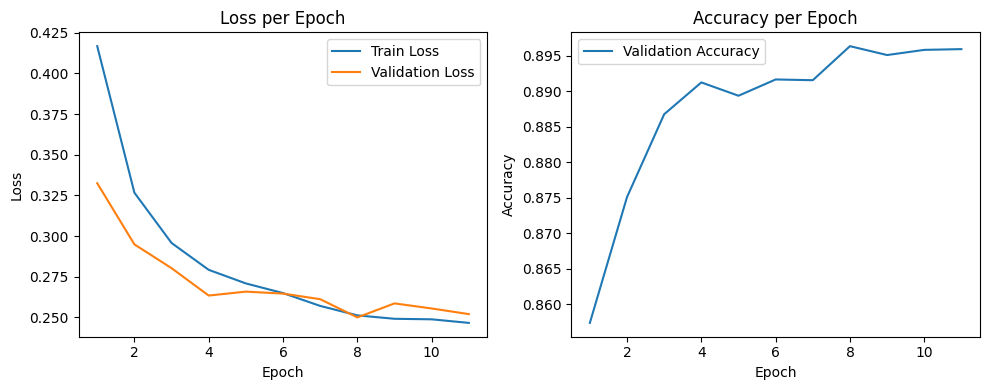

In [7]:
METRICS_PATH = 'checkpoints/CNN/metrics.json'

if os.path.exists(METRICS_PATH):
    with open(METRICS_PATH, 'r') as f:
        metrics = json.load(f)

    epochs = range(1, len(metrics['train_loss']) + 1)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, metrics['train_loss'], label='Train Loss')
    plt.plot(epochs, metrics['val_loss'], label='Validation Loss')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss per Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, metrics['val_acc'], label='Validation Accuracy')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Accuracy per Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Metrics file not found.")
